# 06 · Optimización con Optuna y umbral de decisión — AccessGuard AI

Tres pasos, en orden:

1. **Optuna** busca hiperparámetros del mejor modelo del torneo (notebook 05), maximizando el **ROC-AUC medio en validación cruzada por gerente** (5 pliegues, los mismos del torneo).
2. **Comprobación honesta:** la mejor puntuación de una búsqueda es optimista (se escoge el máximo de muchos intentos). Se compara "por defecto" contra "optimizado" en una **partición por gerente distinta**.
3. **Umbral de decisión:** un modelo da una probabilidad de *aprobar*; el negocio necesita *aprobar / denegar*. Se elige el umbral que **minimiza el costo esperado** (FP = acceso indebido concedido, FN = usuario legítimo bloqueado)
   y se examinan las curvas precisión-recall / F1 de la clase *denegar*.

Al final se entrena el modelo con todo el entrenamiento y se exporta a `models/best_model_iam.joblib`.
**La reserva (`holdout`) y `test.csv` no se usan**: se abrirán una sola vez en la etapa de validación.

In [1]:
import sys, warnings, json, time
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, optuna
from sklearn.metrics import roc_auc_score
from config.settings import PROCESSED_DIR, REPORTS_DIR, ROOT as PROJECT_ROOT, SEED, TARGET, GROUP_COL, COST_FP, COST_FN
MODELS_DIR = PROJECT_ROOT / "models"
for d in (PROCESSED_DIR, REPORTS_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)               # se crean si no existen
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 1. Finalista y datos

Se lee el resultado del torneo (`reports/05_finalistas.json`) y se toma el mejor.

In [2]:
from accessguard.modeling import (best_threshold, build_model, build_pipeline, expected_cost, f1_curve,
                                  fold_matrices, make_cv, metrics_at, suggest_params)

finalists = json.loads((REPORTS_DIR / "05_finalistas.json").read_text(encoding="utf-8"))
MODEL = finalists["mejor"]
print("Finalistas del torneo:", finalists["finalistas"], "→ se optimiza:", MODEL)

train = pd.read_csv(PROCESSED_DIR / "train_clean.csv")
y = train[TARGET].to_numpy(); X = train.drop(columns=TARGET)
folds = fold_matrices(X, y, X[GROUP_COL], make_cv(5, SEED), seed=SEED)
print(f"{len(X):,} filas · {X[GROUP_COL].nunique():,} gerentes · {folds[0][0].shape[1]} variables · 5 pliegues por gerente")

Finalistas del torneo: ['LogReg ElasticNet', 'LogReg L2 (baseline)'] → se optimiza: LogReg ElasticNet


26,215 filas · 3,360 gerentes · 29 variables · 5 pliegues por gerente


## 2. Estudio de Optuna

Optuna usa un muestreador bayesiano (TPE): aprende qué zonas del espacio dieron mejor ROC-AUC y explora más ahí. El espacio de búsqueda está acotado por conocimiento del algoritmo
(`suggest_params` en `src/accessguard/modeling.py`). La semilla fija hace la búsqueda reproducible.

In [3]:
N_TRIALS = 40
fold_aucs = {}   # ROC-AUC por pliegue de cada ensayo (para ver la dispersión)

def objective(trial):
    params = suggest_params(trial, MODEL)
    aucs = []
    for X_tr, y_tr, X_va, y_va, _ in folds:
        p = build_model(MODEL, params, seed=SEED).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
        aucs.append(roc_auc_score(y_va, p))
    trial.set_user_attr("auc_std", float(np.std(aucs, ddof=1)))
    return float(np.mean(aucs))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name=f"iam-{MODEL}")
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS)
print(f"{N_TRIALS} ensayos en {time.time() - t0:.0f} s · mejor ROC-AUC (CV) = {study.best_value:.4f} (ensayo {study.best_trial.number})")
print("mejores parámetros:", study.best_params)

40 ensayos en 69 s · mejor ROC-AUC (CV) = 0.7335 (ensayo 38)
mejores parámetros: {'C': 0.0457958859837167, 'l1_ratio': 0.11277278436524751}


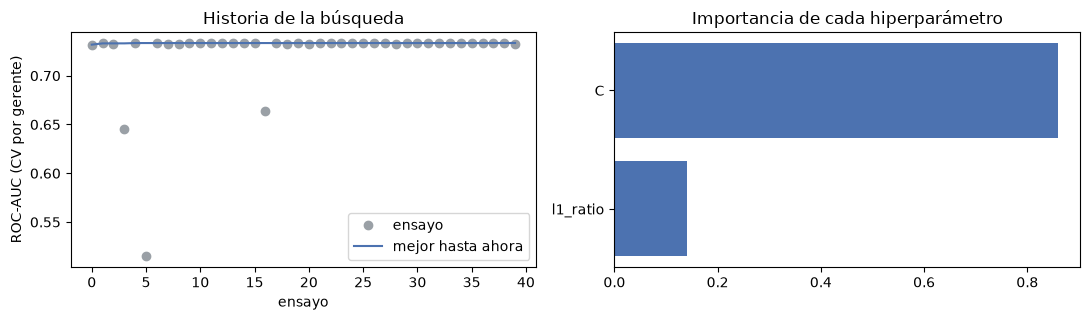

,number,value,user_attrs_auc_std,params_C,params_l1_ratio
38,38,0.7335,0.0072,0.0458,0.1128
37,37,0.7335,0.0073,0.1195,0.2800
4,4,0.7335,0.0073,0.2538,0.6873
12,12,0.7335,0.0072,0.1761,0.6366
14,14,0.7335,0.0073,0.3013,0.8158


In [4]:
vals = [t.value for t in study.trials]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(vals, "o", color="#9aa0a6", label="ensayo"); axes[0].plot(np.maximum.accumulate(vals), "-", color="#4c72b0", label="mejor hasta ahora")
axes[0].set_xlabel("ensayo"); axes[0].set_ylabel("ROC-AUC (CV por gerente)"); axes[0].legend(); axes[0].set_title("Historia de la búsqueda")
imp = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
axes[1].barh(imp.index, imp.values, color="#4c72b0"); axes[1].set_title("Importancia de cada hiperparámetro")
plt.tight_layout(); plt.show()
trials_df = study.trials_dataframe()[["number", "value", "user_attrs_auc_std"] + [c for c in study.trials_dataframe().columns if c.startswith("params_")]]
trials_df.sort_values("value", ascending=False).head(5).round(4)

## 3. Comprobación honesta: ¿optimizar sirvió?

El `best_value` de la búsqueda es optimista. Se reevalúa **por defecto** vs **optimizado** con una validación cruzada por gerente **con otra semilla** (otros grupos de gerentes en cada pliegue).
Si la diferencia es menor que la desviación entre pliegues, la mejora **no se distingue del ruido**.

In [5]:
folds_b = fold_matrices(X, y, X[GROUP_COL], make_cv(5, 7), seed=7)
def cv_auc(params):
    out = []
    for X_tr, y_tr, X_va, y_va, _ in folds_b:
        p = build_model(MODEL, params, seed=SEED).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
        m = metrics_at(y_va, p); out.append((m["roc_auc"], m["pr_auc_deny"]))
    return np.array(out)

default_res, tuned_res = cv_auc(None), cv_auc(study.best_params)
diff = tuned_res[:, 0] - default_res[:, 0]
check = pd.DataFrame({
    "ROC-AUC": [default_res[:, 0].mean(), tuned_res[:, 0].mean()], "± ROC": [default_res[:, 0].std(ddof=1), tuned_res[:, 0].std(ddof=1)],
    "PR-AUC denegar": [default_res[:, 1].mean(), tuned_res[:, 1].mean()], "± PR": [default_res[:, 1].std(ddof=1), tuned_res[:, 1].std(ddof=1)],
}, index=["por defecto", "optimizado"])
display(check.round(4))
print(f"Mejora de ROC-AUC (optimizado − defecto): {diff.mean():+.4f} · gana en {(diff > 0).sum()} de 5 pliegues · mejora/ruido = {diff.mean() / diff.std(ddof=1):.2f}")
print("Lectura:", "la mejora es consistente" if (diff > 0).all() and diff.mean() > diff.std(ddof=1) else "la mejora NO es distinguible del ruido; el modelo optimizado no es claramente mejor que el de por defecto")

,ROC-AUC,± ROC,PR-AUC denegar,± PR
por defecto,0.7311,0.0203,0.1907,0.0306
optimizado,0.7317,0.0204,0.1921,0.0312


Mejora de ROC-AUC (optimizado − defecto): +0.0006 · gana en 4 de 5 pliegues · mejora/ruido = 0.70
Lectura: la mejora NO es distinguible del ruido; el modelo optimizado no es claramente mejor que el de por defecto


## 4. Predicciones fuera de pliegue del modelo optimizado

Para ajustar el umbral se necesitan probabilidades de filas que el modelo **no vio al entrenar**: las predicciones OOF de los 5 pliegues (semilla 42).

In [6]:
p_oof = np.zeros(len(y))
for X_tr, y_tr, X_va, y_va, idx_va in folds:
    p_oof[idx_va] = build_model(MODEL, study.best_params, seed=SEED).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
m = metrics_at(y, p_oof)
print(f"OOF · ROC-AUC = {m['roc_auc']:.4f} · PR-AUC denegar = {m['pr_auc_deny']:.4f} (azar = {1 - y.mean():.4f})")

OOF · ROC-AUC = 0.7290 · PR-AUC denegar = 0.1803 (azar = 0.0579)


## 5. Ajuste del umbral de decisión

Regla: **aprobar si p(aprobar) ≥ umbral**. Costo por solicitud = (`COST_FP`·FP + `COST_FN`·FN) / N.

* FP = se **aprueba** a quien debía **denegarse** (acceso indebido; error caro).
* FN = se **deniega** a quien debía **aprobarse** (usuario legítimo bloqueado; ticket y horas perdidas).

> **Los costos son supuestos de trabajo** (`config/settings.py`), no datos medidos. Hay que validarlos con Seguridad/Riesgos; por eso hay un análisis de sensibilidad más abajo.

Supuestos: COST_FP = 2,000 USD · COST_FN = 40 USD · razón FP/FN = 50


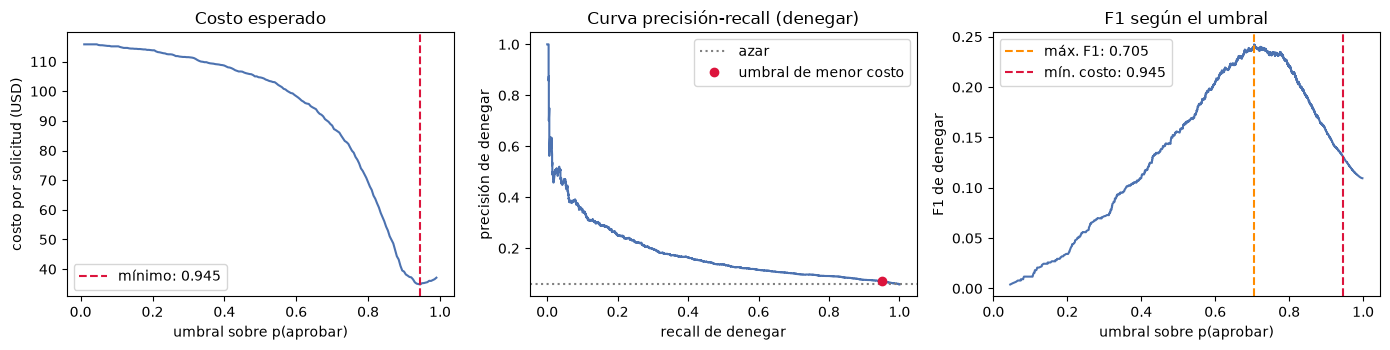

In [7]:
print(f"Supuestos: COST_FP = {COST_FP:,.0f} USD · COST_FN = {COST_FN:,.0f} USD · razón FP/FN = {COST_FP / COST_FN:.0f}")
thr_cost, cost_min, grid = best_threshold(y, p_oof, COST_FP, COST_FN)
prec, rec, f1, thr_pr = f1_curve(y, p_oof)           # curva de la clase "denegar"
i_f1 = int(np.nanargmax(f1[:-1])); thr_f1 = 1 - thr_pr[i_f1]   # umbral sobre p(aprobar) que maximiza F1 de denegar

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(grid.threshold, grid.cost, color="#4c72b0"); axes[0].axvline(thr_cost, color="crimson", ls="--", label=f"mínimo: {thr_cost:.3f}")
axes[0].set_xlabel("umbral sobre p(aprobar)"); axes[0].set_ylabel("costo por solicitud (USD)"); axes[0].set_title("Costo esperado"); axes[0].legend()
axes[1].plot(rec, prec, color="#4c72b0"); axes[1].axhline(1 - y.mean(), color="grey", ls=":", label="azar")
j = int(np.argmin(np.abs(1 - thr_pr - thr_cost))); axes[1].plot(rec[j], prec[j], "o", color="crimson", label="umbral de menor costo")
axes[1].set_xlabel("recall de denegar"); axes[1].set_ylabel("precisión de denegar"); axes[1].set_title("Curva precisión-recall (denegar)"); axes[1].legend()
axes[2].plot(1 - thr_pr, f1[:-1], color="#4c72b0"); axes[2].axvline(thr_f1, color="darkorange", ls="--", label=f"máx. F1: {thr_f1:.3f}")
axes[2].axvline(thr_cost, color="crimson", ls="--", label=f"mín. costo: {thr_cost:.3f}")
axes[2].set_xlabel("umbral sobre p(aprobar)"); axes[2].set_ylabel("F1 de denegar"); axes[2].set_title("F1 según el umbral"); axes[2].legend()
plt.tight_layout(); plt.show()

In [8]:
strategies = {
    "aprobar todo": 0.0, "denegar todo": 1.01,
    "umbral 0.5 (por defecto)": 0.5,
    f"umbral máx. F1 de denegar ({thr_f1:.3f})": thr_f1,
    f"umbral de menor costo ({thr_cost:.3f})": thr_cost,
}
rows = []
for name, t in strategies.items():
    mm = metrics_at(y, p_oof, t)
    rows.append({"estrategia": name, "costo/solicitud (USD)": expected_cost(y, p_oof, t, COST_FP, COST_FN),
                 "FP (accesos indebidos)": mm["fp"], "FN (legítimos bloqueados)": mm["fn"],
                 "recall denegar": mm["recall_deny"], "F1 denegar": mm["f1_deny"]})
compare = pd.DataFrame(rows).set_index("estrategia")
compare.round(3)

,costo/solicitud (USD),FP (accesos indebidos),FN (legítimos bloqueados),recall denegar,F1 denegar
estrategia,,,,,
aprobar todo,115.812,1518,0,0.000,0.000
denegar todo,37.684,0,24697,1.000,0.109
umbral 0.5 (por defecto),104.655,1366,288,0.100,0.155
umbral máx. F1 de denegar (0.705),87.153,1114,1418,0.266,0.242
umbral de menor costo (0.945),34.817,76,19018,0.950,0.131


**Lectura.** El umbral de menor costo es muy alto: como un acceso indebido cuesta 50 veces más que bloquear a un usuario legítimo, conviene **denegar o enviar a revisión ante la mínima duda**. Eso mueve el modelo a un régimen de *recall de denegar* alto y precisión baja:
atrapa casi todas las denegaciones, a costa de bloquear a muchos legítimos. Compáralo con el **umbral de máximo F1**, que busca otro equilibrio y **ignora los costos**.

### ¿Es real el ahorro frente a "denegar todo"?

El umbral se eligió con las mismas predicciones OOF con las que se mide, así que el costo es algo optimista. Remuestreamos **gerentes** (no filas) para ver cuánto varía el ahorro frente a la política trivial "denegar todo":

In [9]:
rng = np.random.default_rng(SEED)
mgr = X[GROUP_COL].to_numpy(); uniq = np.unique(mgr)
idx_by = pd.Series(np.arange(len(mgr))).groupby(mgr).apply(np.array)
savings = []
for _ in range(500):
    pick = rng.choice(uniq, len(uniq), replace=True)
    ii = np.concatenate([idx_by.loc[g] for g in pick])
    c_model = expected_cost(y[ii], p_oof[ii], thr_cost, COST_FP, COST_FN)
    c_deny = expected_cost(y[ii], p_oof[ii], 1.01, COST_FP, COST_FN)
    savings.append(c_deny - c_model)
lo, hi = np.percentile(savings, [2.5, 97.5])
print(f"Ahorro por solicitud frente a 'denegar todo': {np.mean(savings):.2f} USD · IC 95 % [{lo:.2f}, {hi:.2f}]")
print("Lectura:", "el intervalo queda por encima de 0: el modelo mejora a la política trivial con estos costos" if lo > 0
      else "el intervalo incluye 0: con estos costos el modelo NO se distingue de 'denegar todo'")

Ahorro por solicitud frente a 'denegar todo': 2.83 USD · IC 95 % [1.16, 4.28]
Lectura: el intervalo queda por encima de 0: el modelo mejora a la política trivial con estos costos


### Sensibilidad a los costos supuestos

Como los costos no son medidos, se recalcula el umbral óptimo para distintas razones FP/FN (con `COST_FN` fijo). Si el umbral y el ahorro cambian mucho, **la decisión depende del costo real** y hay que conseguirlo antes de desplegar.

In [10]:
rows = []
for c_fp in [100, 200, 500, 1000, 2000, 5000, 10000]:
    t, c, _ = best_threshold(y, p_oof, c_fp, COST_FN)
    mm = metrics_at(y, p_oof, t)
    rows.append({"COST_FP": c_fp, "razón FP/FN": c_fp / COST_FN, "umbral óptimo": t, "costo modelo": c,
                 "costo aprobar todo": expected_cost(y, p_oof, 0.0, c_fp, COST_FN), "costo denegar todo": expected_cost(y, p_oof, 1.01, c_fp, COST_FN),
                 "recall denegar": mm["recall_deny"]})
sens = pd.DataFrame(rows).set_index("COST_FP")
sens["ahorro vs mejor política trivial"] = sens[["costo aprobar todo", "costo denegar todo"]].min(axis=1) - sens["costo modelo"]
sens.to_csv(REPORTS_DIR / "06_sensibilidad_costos.csv")
sens.round(3)

,razón FP/FN,umbral óptimo,costo modelo,costo aprobar todo,costo denegar todo,recall denegar,ahorro vs mejor política trivial
COST_FP,,,,,,,
100,2.5,0.440,5.621,5.791,37.684,0.082,0.169
200,5.0,0.625,10.591,11.581,37.684,0.181,0.990
500,12.5,0.815,21.823,28.953,37.684,0.505,7.130
1000,25.0,0.895,29.606,57.906,37.684,0.829,8.078
2000,50.0,0.945,34.817,115.812,37.684,0.950,2.867
5000,125.0,0.985,36.718,289.529,37.684,0.999,0.966
10000,250.0,0.985,36.909,579.058,37.684,0.999,0.775


## 6. Modelo final y exportación

Se entrena el pipeline completo (`IAMFeatureBuilder` + modelo con los mejores parámetros) con **todo** el entrenamiento y se guarda un *paquete* con el pipeline, el umbral y los metadatos en `models/best_model_iam.joblib`.
Para cargarlo hace falta tener `src/` en el `PYTHONPATH` (el pipeline usa `accessguard.engineering`).

Uso: `p = bundle["pipeline"].predict_proba(X)[:, 1]` y **aprobar si `p >= bundle["threshold"]`**.

In [11]:
final_pipe = build_pipeline(MODEL, study.best_params, seed=SEED).fit(X, y)

bundle = {
    "pipeline": final_pipe,
    "threshold": float(thr_cost),
    "decision_rule": "aprobar (ACTION=1) si p_approve >= threshold; en otro caso denegar / enviar a revisión",
    "model_name": MODEL, "best_params": study.best_params,
    "input_columns": list(X.columns),
    "cost_assumptions_usd": {"COST_FP": COST_FP, "COST_FN": COST_FN, "nota": "supuestos de trabajo, no costos medidos"},
    "cv_metrics_oof": {"roc_auc": float(m["roc_auc"]), "pr_auc_deny": float(m["pr_auc_deny"]),
                       "cost_per_request_at_threshold": float(cost_min), "scheme": "StratifiedGroupKFold 5 por MGR_ID, semilla 42"},
    "holdout_used": False,
}
path = MODELS_DIR / "best_model_iam.joblib"
joblib.dump(bundle, path)

# comprobación: recargar y predecir
loaded = joblib.load(path)
sample = X.sample(5, random_state=SEED)
p_new = loaded["pipeline"].predict_proba(sample)[:, 1]
assert np.allclose(p_new, final_pipe.predict_proba(sample)[:, 1])
print(f"Guardado: {path} ({path.stat().st_size / 1024:.0f} KB)")
print("probabilidades de ejemplo:", p_new.round(3), "→ decisión:", np.where(p_new >= loaded["threshold"], "aprobar", "denegar/revisar"))

(REPORTS_DIR / "06_best_params.json").write_text(json.dumps({
    "model": MODEL, "best_params": study.best_params, "n_trials": N_TRIALS, "cv_roc_auc_search": study.best_value,
    "threshold_min_cost": float(thr_cost), "threshold_max_f1_deny": float(thr_f1), "cost_per_request_oof": float(cost_min),
    "cost_assumptions": bundle["cost_assumptions_usd"],
}, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
compare.to_csv(REPORTS_DIR / "06_comparacion_umbrales.csv")

Guardado: D:\Carpetas de sistema\Escritorio\Laboratorio avanzado analitica\ab-casos-avanzados2026v2\laboratorio-avanzado-iam\models\best_model_iam.joblib (8601 KB)
probabilidades de ejemplo: [0.926 0.995 1.    1.    1.   ] → decisión: ['denegar/revisar' 'aprobar' 'aprobar' 'aprobar' 'aprobar']


## 7. Qué concluir (y qué no)

* El modelo exportado es el mejor del torneo con hiperparámetros de Optuna y un umbral de **menor costo bajo supuestos**. Las métricas mostradas son de validación cruzada por gerente (OOF), **no** de la reserva.
* Mira la comprobación honesta (sección 3): si la mejora de Optuna no supera el ruido, el modelo "por defecto" es igual de bueno y más simple.
* Mira el intervalo del ahorro frente a "denegar todo" y la tabla de sensibilidad: el valor del modelo depende de **costos que aún no se han validado**.
* El umbral es alto porque el error caro es aprobar de más; operativamente implica **muchos casos a revisión manual**. Falta modelar `COST_REVIEW` (revisión manual) para una política de tres salidas (aprobar / revisar / denegar): queda como mejora.
* **Pendiente (etapa de validación):** abrir la reserva (`holdout_clean.csv`) **una sola vez** con este modelo y este umbral, e interpretar variables (SHAP).